In [1]:
## 4 autoencoder 
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

In [2]:
#normalize and reshape 
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

In [3]:
#select normal data train on 0
x_train_normal = x_train[y_train == 0]

x_test_normal = x_test[y_test == 0]
x_test_anomaly = x_test[y_test != 0]

In [4]:
#encoder
encoder = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu')
])

In [5]:
#decoder
decoder = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32,)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(784, activation='sigmoid')
])

In [6]:
autoencoder = tf.keras.Sequential([encoder, decoder])

In [7]:
#compile model
autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)
#Adam = Optimizer.
#MSE = Loss function
#MAE = Evaluation metric

In [8]:
#train
history = autoencoder.fit(
    x_train_normal,
    x_train_normal,
    epochs=5,
    batch_size=256,
    validation_split=0.1
)

Epoch 1/5
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - loss: 0.1523 - mae: 0.3407 - val_loss: 0.0698 - val_mae: 0.1442
Epoch 2/5
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0645 - mae: 0.1344 - val_loss: 0.0574 - val_mae: 0.1257
Epoch 3/5
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0519 - mae: 0.1172 - val_loss: 0.0449 - val_mae: 0.1039
Epoch 4/5
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0437 - mae: 0.1004 - val_loss: 0.0403 - val_mae: 0.0952
Epoch 5/5
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0395 - mae: 0.0951 - val_loss: 0.0364 - val_mae: 0.0903


In [9]:
#calaulate thersold 
pred = autoencoder.predict(x_train_normal)

error = np.mean(np.square(x_train_normal - pred), axis=1)

threshold = np.percentile(error, 95)

print("Threshold:", threshold)

186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
Threshold: 0.06417945


In [10]:
#test normal and anomaly
test_images = np.concatenate([
    x_test_normal[:100],
    x_test_anomaly[:100]
])

predictions = autoencoder.predict(test_images)

test_error = np.mean(
    np.square(test_images - predictions), axis=1
)

results = test_error > threshold
#Select 100 normal images.
# Select 100 anomaly images
# Combine both datasets.
# Reconstruct the images.
# Calculate reconstruction error.
# Compare error with threshold.

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


In [11]:
print("Total Images:", len(test_images))
print("Detected Anomalies:", np.sum(results))
print("Detected Normal:", np.sum(~results))

Total Images: 200
Detected Anomalies: 97
Detected Normal: 103


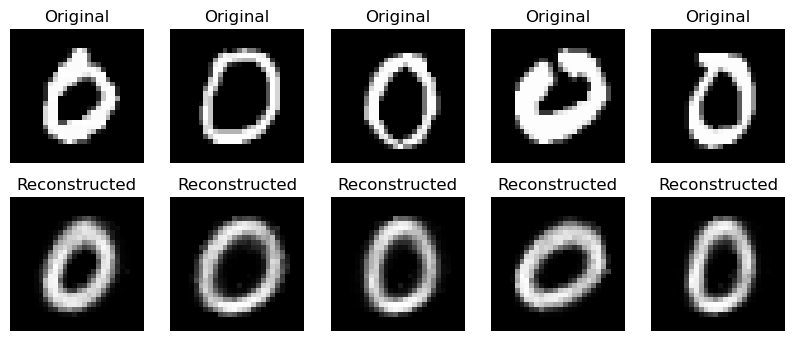

In [13]:

plt.figure(figsize=(10, 4))

for i in range(5):
    plt.subplot(2, 5, i+1)
    plt.imshow(test_images[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    plt.subplot(2, 5, i+6)
    plt.imshow(predictions[i].reshape(28, 28), cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')

plt.show()

